# Imports

In [1]:
%pip install tf2onnx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.1/839.1 kB 9.7 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 48.1 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from keras.utils import image_dataset_from_directory
from keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.optimizers import Adam
from keras import Model
from keras.models import load_model
import kagglehub
import os
import shutil
import tensorflow as tf
import matplotlib.pyplot as plt
import tf2onnx
import onnx
import onnxruntime as ort
import datetime
from PIL import Image
import numpy as np
import pandas as pd

# Dataset dowload

In [4]:
# Dataset 1
path = Path(kagglehub.dataset_download("ahmedmohamedabdallah/breastcancer"))
print("Path to dataset:", path)

Path to dataset: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer


# Analysis and data preprocessment

In [5]:
# Explore data directory
data = Path("/kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data")
print(os.listdir(data))

['Cancer', 'Negative']


In [6]:
classes = list(os.listdir(data))
cancer_data = Path(os.path.join(data, classes[0])) # Bibliography: [Ref.1]
no_cancer_data = Path(os.path.join(data, classes[1])) # Bibliography: [Ref.1]
print(f"Classes: {classes}")
print(f"Cancer images path: {cancer_data}")
print(f"No cancer images path: {no_cancer_data}")

Classes: ['Cancer', 'Negative']
Cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Cancer
No cancer images path: /kaggle/input/datasets/ahmedmohamedabdallah/breastcancer/Data/Negative


In [7]:
# Explore images format
def check_formats(path_data_to_check: Path) -> dict:
    res = {}
    key_res = str(path_data_to_check).split("/")[-1]
    res[key_res] = []
    for image in os.listdir(path_data_to_check):
        _, img_format = image.split(".")
        if img_format not in res[key_res]:
            res[key_res].append(img_format)
    return res

cancer_formats = check_formats(cancer_data)
print(cancer_formats)
no_cancer_formats = check_formats(no_cancer_data)
print(no_cancer_formats)

{'Cancer': ['jpg']}
{'Negative': ['jpg']}


In [8]:
# Check number of images in each class
num_cancer = len(os.listdir(cancer_data))
num_no_cancer = len(os.listdir(no_cancer_data))
print(f"Number of pictures of class 'Cancer : {num_cancer}'")
print(f"Number of pictures of class 'No Cancer : {num_no_cancer}'")

Number of pictures of class 'Cancer : 410'
Number of pictures of class 'No Cancer : 410'


In [9]:
# Prepare data for train, validation, test split
images = []
classes_labels = []

for class_name in os.listdir(data):
    class_path = Path(os.path.join(data, class_name))
    for image in class_path.iterdir():
        images.append(image)
        classes_labels.append(class_name)

# Split data into train, validation and test sets
paths_train, paths_temp, labels_train, labels_temp = train_test_split( # 80% of data for training, 10% for validation and 10% for testing
    images, classes_labels, train_size=0.8  # Bibliography: [Ref.2] and Bibliography: [Ref.3]
)
paths_val, paths_test, labels_val, labels_test = train_test_split(  # Bibliography: [Ref.2] and Bibliography: [Ref.3]
    paths_temp, labels_temp, train_size=0.5
)

print(f"Number of images for training: {len(paths_train)}")
print(f"Number of images for validation: {len(paths_val)}")
print(f"Number of images for testing: {len(paths_test)}")

Number of images for training: 656
Number of images for validation: 82
Number of images for testing: 82


In [10]:
# Create train, validation and test folders and copy the images in there
os.makedirs("train", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("train/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("train/Negative", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("validation/Negative", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test/Cancer", exist_ok=True) # Bibliography: [Ref.4]
os.makedirs("test/Negative", exist_ok=True) # Bibliography: [Ref.4]

def copy_images(images_paths: Path, labels: Path, destination: Path)-> None:
    # Empty folders everytime
    for file in Path(os.path.join(destination, "Cancer")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    for file in Path(os.path.join(destination, "Negative")).iterdir():
        file.unlink() # Bibliography: [Ref.5]
    # Copy the images
    for image_path, label in zip(images_paths, labels): # Bibliography: [Ref.6]
        if label == "Cancer":
            shutil.copy(image_path, os.path.join(destination, "Cancer")) # Bibliography: [Ref.7]
        elif label == "Negative":
            shutil.copy(image_path, os.path.join(destination, "Negative")) # Bibliography: [Ref.7]

copy_images(paths_train, labels_train, Path("train"))
copy_images(paths_test, labels_test, Path("test"))
copy_images(paths_val, labels_val, Path("validation"))

In [11]:
# Create Tensorflow datasets
train_dir = Path("/kaggle/working/train")
val_dir = Path("/kaggle/working/validation")
test_dir = Path("/kaggle/working/test")

train_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    train_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)
val_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    val_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)
test_dataset = tf.keras.utils.image_dataset_from_directory( # Bibliography: [Ref.8]
    test_dir,
    labels="inferred",
    color_mode="grayscale",
    batch_size=32,
    image_size=(224, 224)
)

Found 656 files belonging to 2 classes.


I0000 00:00:1793718595.252690      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793718595.256424      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 82 files belonging to 2 classes.
Found 82 files belonging to 2 classes.


# Architecture definition

In [12]:
# Extractor block
input_layer = Input(shape=(224, 224, 1)) # 1 because it's grayscale # Bibliography: [Ref.9]
conv_layer_1 = Conv2D(filters=32, kernel_size=(5, 5), padding="same", activation="relu")(input_layer) # Bibliography: [Ref.10]
max_pooling_layer_1 = MaxPooling2D()(conv_layer_1) # Bibliography: [Ref.11]
conv_layer_2 = Conv2D(filters=64, kernel_size=(3, 3), padding="same", activation="relu")(max_pooling_layer_1) # Bibliography: [Ref.10]
max_pooling_layer_2 = MaxPooling2D()(conv_layer_2) # Bibliography: [Ref.11]
conv_layer_3 = Conv2D(filters=128, kernel_size=(3, 3), padding="same", activation="relu")(max_pooling_layer_2) # Bibliography: [Ref.10]
max_pooling_layer_3 = MaxPooling2D()(conv_layer_3) # Bibliography: [Ref.11]
conv_layer_3 = Conv2D(filters=256, kernel_size=(3, 3), padding="same", activation="relu")(max_pooling_layer_3) # Bibliography: [Ref.10]
global_pooling_layer = GlobalAveragePooling2D()(conv_layer_3 )# Bibliography: [Ref.12]
# Classification block
dense_hidden_layer = Dense(1024, activation="relu")(global_pooling_layer) # Bibliography: [Ref.13]
dropout_layer = Dropout(0.5)(dense_hidden_layer) # Bibliography: [Ref.14]
dense_classification_layer = Dense(2, activation="softmax")(dropout_layer) # Bibliography: [Ref.13]

model = Model(inputs=input_layer, outputs=dense_classification_layer) # Bibliography: [Ref.15]

In [13]:
# Model architecture report
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         2,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 653,570 (2.49 MB)

 Trainable params: 653,570 (2.49 MB)

 Non-trainable params: 0 (0.00 B)

# Compilation, training and evaluation

In [14]:
# Model compilation
optimizer = Adam(learning_rate=0.001) # Bibliography: [Ref.16]
model.compile( # Bibliography: [Ref.17]
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy", # Bibliography: [Ref.18]
    metrics=["accuracy"]
)

In [15]:
# Callbacks
early_stopping = EarlyStopping( # Bibliography: [Ref.19]
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
os.makedirs("checkpoints", exist_ok=True) # Bibliography: [Ref.4]
model_checkpoint = ModelCheckpoint( # Bibliography: [Ref.20]
    Path("checkpoints/best.h5"),
    monitor="val_loss",
    save_best_only=True
)
reduce_lr = ReduceLROnPlateau( # Bibliography: [Ref.39]
    monitor="val_loss",
    patience=2,
    verbose=1
)

In [17]:
# Training
train_model = model.fit( # Bibliography: [Ref.17]
    train_dataset,
    epochs=300,
    validation_data=val_dataset,
    callbacks=[early_stopping, model_checkpoint, reduce_lr]
)

Epoch 1/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.5334 - loss: 2.7787

21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 369ms/step - accuracy: 0.6006 - loss: 1.3315 - val_accuracy: 0.8171 - val_loss: 0.4527 - learning_rate: 0.0010
Epoch 2/300
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8532 - loss: 0.4025

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8399 - loss: 0.4229 - val_accuracy: 0.9146 - val_loss: 0.3602 - learning_rate: 0.0010
Epoch 3/300
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.8647 - loss: 0.3851

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.8735 - loss: 0.3624 - val_accuracy: 0.9146 - val_loss: 0.2855 - learning_rate: 0.0010
Epoch 4/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8887 - loss: 0.3484 - val_accuracy: 0.8049 - val_loss: 0.4471 - learning_rate: 0.0010
Epoch 5/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8166 - loss: 0.4498

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8567 - loss: 0.3822 - val_accuracy: 0.9146 - val_loss: 0.2753 - learning_rate: 0.0010
Epoch 6/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8994 - loss: 0.3110 - val_accuracy: 0.9024 - val_loss: 0.2909 - learning_rate: 0.0010
Epoch 7/300
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9074 - loss: 0.3113

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9162 - loss: 0.2700 - val_accuracy: 0.9390 - val_loss: 0.2373 - learning_rate: 0.0010
Epoch 8/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.9070 - loss: 0.2902 - val_accuracy: 0.9390 - val_loss: 0.2522 - learning_rate: 0.0010
Epoch 9/300
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9019 - loss: 0.2514
Epoch 9: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9085 - loss: 0.2755 - val_accuracy: 0.9268 - val_loss: 0.2549 - learning_rate: 0.0010
Epoch 10/300
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9177 - loss: 0.2543 - val_accuracy: 0.9268 - val_loss: 0.2487 - learning_rate: 1.0000e-04
Epoch 11/300
20/21 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9133 - loss: 0.2509
Epoch 11: ReduceLROnPlateau reducing learning rate to 1.0000000474974514e-05.
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9101 - loss: 0.2487 - val_acc

In [18]:
# Model evaluation
test_loss, test_accuracy = model.evaluate(test_dataset) # Bibliography: [Ref.21]
print(f"Testing loss: {test_loss}")
print(f"Testing accuracy: {(test_accuracy*100)}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9146 - loss: 0.2995
Testing loss: 0.29949289560317993
Testing accuracy: 91.46341681480408%


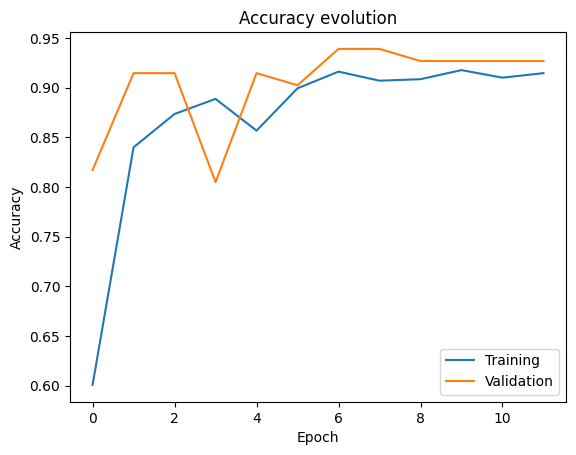

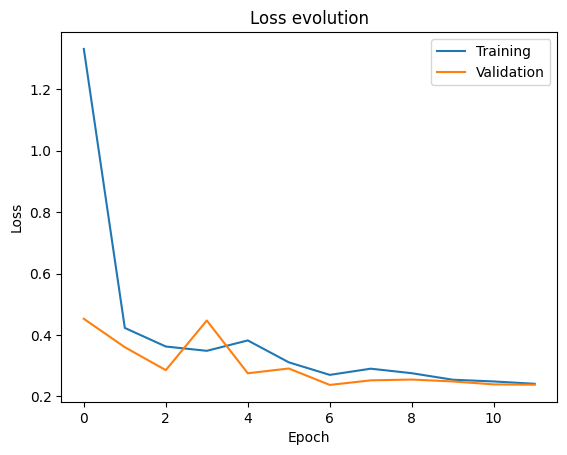

In [19]:
# Model evaluation - Graphics
plt.figure()
plt.plot(train_model.history["accuracy"]) # Bibliography: [Ref.22]
plt.plot(train_model.history["val_accuracy"]) # Bibliography: [Ref.22]
plt.title("Accuracy evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.23]
plt.ylabel("Accuracy") # Bibliography: [Ref.24]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.25]
plt.show()

plt.figure()
plt.plot(train_model.history["loss"]) # Bibliography: [Ref.22]
plt.plot(train_model.history["val_loss"]) # Bibliography: [Ref.22]
plt.title("Loss evolution")
plt.xlabel("Epoch") # Bibliography: [Ref.23]
plt.ylabel("Loss") # Bibliography: [Ref.24]
plt.legend(["Training", "Validation"]) # Bibliography: [Ref.25]
plt.show()

# Model exportation to onnx

In [20]:
# Conversion from .h5 to onnx -  # Bibliography: [Ref.26]
model_keras = load_model("checkpoints/best.h5")
onnx_model, _ = tf2onnx.convert.from_keras(model_keras)
name_onnx = f"Exp3-{datetime.datetime.now().strftime("%d-%m-%Y")}-CNN.onnx" # Bibliography: [Ref.27]
onnx.save(onnx_model, name_onnx)

I0000 00:00:1793718656.067296      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1793718656.067458      49 single_machine.cc:376] Starting new session
I0000 00:00:1793718656.082203      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793718656.083746      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1793718656.188061      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793718656.189601      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 M

# Run inference example

In [21]:
# Load model and inference session # Bibliography: [Ref.28]
session = ort.InferenceSession("/kaggle/working/Exp3-03-11-2026-CNN.onnx")
# Obtain inputs and outputs # Bibliography: [Ref.29]
inputs = session.get_inputs()
outputs = session.get_outputs()
print("---------- Inputs ----------")
for elem in inputs:
    print(elem)
print("---------- Outputs ----------")
for elem in outputs:
    print(elem)

---------- Inputs ----------
NodeArg(name='input_layer', type='tensor(float)', shape=['unk__37', 224, 224, 1])
---------- Outputs ----------
NodeArg(name='dense_1', type='tensor(float)', shape=['unk__38', 2])


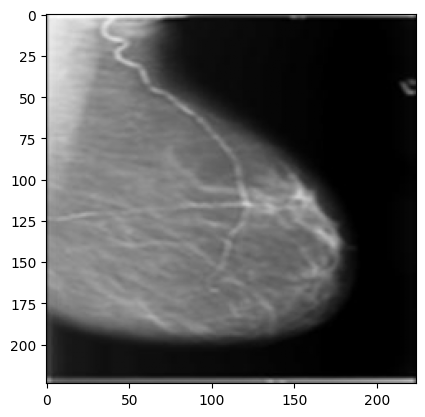

In [22]:
# Image processing to adapt it to model input # Bibliography: [Ref.30] and # Bibliography: [Ref.31]
img = Path("/kaggle/working/test/Cancer/101.jpg")
pict = Image.open(img).convert("L") # Open picture and convert to grayscale
pict = pict.resize((224, 224)) # Resize to 224 x 224
# Bibliography: [Ref.28] -> ONNX runtime needs inputs in NumPy format
pict = np.array(pict, dtype=np.float32) # Bibliography: [Ref.32] # Bibliography: [Ref.33]

plt.figure()
plt.imshow(pict, cmap="gray") # Bibliography: [Ref.34] # Bibliography: [Ref.35] # Bibliography: [Ref.36]
plt.show()

<strong>Error when running inference:</strong>

```python
    
    ---------------------------------------------------------------------------
    InvalidArgument                           Traceback (most recent call last)
    /tmp/ipykernel_48/3177531922.py in <cell line: 0>()
    ----> 1 predictions = session.run(
          2     [output_name],
          3     {input_name: pict}
          4 )[0]
          5 

    /usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py in run(self, output_names, input_feed, run_options)
        393             output_names = [output.name for output in self._outputs_meta]
        394         try:
    --> 395             return self._sess.run(output_names, input_feed, run_options)
        396         except C.EPFail as err:
        397             if self._enable_fallback:

    InvalidArgument: [ONNXRuntimeError] : 2 : INVALID_ARGUMENT : Invalid rank for input: input_layer Got: 2 Expected: 4 Please fix either the inputs/outputs or the model.
```

- ```# Bibliography: [Ref.37]``` Is a thread from a GitHub issue where you can read why the error is appearing. $\rightarrow$ check input shape

In [23]:
pict = np.reshape(pict, (-1, 224, 224, 1)) # Bibliography: [Ref.38]
predictions = session.run(
    [outputs[0].name],
    {inputs[0].name: pict}
)

# When creating the datasets labels="inferred" abels are generated from the directory structure.
# Labels are sorted according to the alphanumeric order of the image file paths
# print(train_dataset.class_names) returns ['Cancer', 'Negative'] then when printing a prediction:
# [[Cancer_probability_prediction Negative_probability_prediction]]
predictions_dict = {
    "Cancer probability": f"{predictions[0][0][0] * 100}%",
    "Negative probability": f"{predictions[0][0][1] * 100}%"
}
results_df = pd.DataFrame.from_dict(predictions_dict, orient="index", columns=["Probability"])
results_df

,Probability
Cancer probability,99.51458740234375%
Negative probability,0.4854108691215515%


# Bibliographic references

<div style="background-color: #c3fac4; border-color: #dfb54; border-left: 5px solid #dfb5b4; padding: 0.5em;">

<strong>Citation style: ISO 690.<strong>

[Ref.1] -- <em>Python|os.path.join() method</em> [online][accessed: 31st October 2026]. Available at: <a href="https://www.geeksforgeeks.org/python/python-os-path-join-method/">https://www.geeksforgeeks.org/python/python-os-path-join-method/</a>

[Ref.2] -- <em>train_test_split</em> [online][accessed: 1st November 2026]. Available at: <a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html">https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html</a>

[Ref.3] -- <em>Sklearn train_test_split: Dividir datos para Machine Learning en Python</em> [online][accessed: 31st October 2026]. Available at: <a href="https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split">https://docs.kanaries.net/es/topics/Scikit-Learn/sklearn-train-test-split</a>

[Ref.4] -- <em>Python: Create a Directory if it Doesn’t Exist</em> [online][accessed: 1st November 2026]. Available at: <a href="https://datagy.io/python-create-directory-if-doesnt-exist/">https://datagy.io/python-create-directory-if-doesnt-exist/</a>

[Ref.5] -- <em>How to empty an entire directory with Python?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.tradingcode.net/python/empty-clear-directory/">https://www.tradingcode.net/python/empty-clear-directory/</a>

[Ref.6] -- <em>Python zip() Function</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.w3schools.com/python/ref_func_zip.asp">https://www.w3schools.com/python/ref_func_zip.asp</a>

[Ref.7] -- <em>How do I copy a file?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://stackoverflow.com/questions/123198/how-do-i-copy-a-file">https://stackoverflow.com/questions/123198/how-do-i-copy-a-file</a>

[Ref.8] -- <em>Image data loading</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/data_loading/image/">https://keras.io/api/data_loading/image/</a>

[Ref.9] -- <em>Input object</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/input/">https://keras.io/api/layers/core_layers/input/</a>

[Ref.10] -- <em>Conv2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/convolution_layers/convolution2d/">https://keras.io/api/layers/convolution_layers/convolution2d/</a>

[Ref.11] -- <em>MaxPooling2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/pooling_layers/max_pooling2d/">https://keras.io/api/layers/pooling_layers/max_pooling2d/</a>

[Ref.12] -- <em>GlobalAveragePooling2D layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/pooling_layers/global_average_pooling2d/">https://keras.io/api/layers/pooling_layers/global_average_pooling2d/</a>

[Ref.13] -- <em>Dense layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/core_layers/dense/">https://keras.io/api/layers/core_layers/dense/</a>

[Ref.14] -- <em>Dropout layer</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/layers/regularization_layers/dropout/">https://keras.io/api/layers/regularization_layers/dropout/</a>

[Ref.15] -- <em>The Model class</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/models/model/">https://keras.io/api/models/model/</a>

[Ref.16] -- <em>Adam</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/optimizers/adam/">https://keras.io/api/optimizers/adam/</a>

[Ref.17] -- <em>Model training APIs</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/models/model_training_apis/">https://keras.io/api/models/model_training_apis/</a>

[Ref.18] -- <em>Probabilistic losses</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class">https://keras.io/api/losses/probabilistic_losses/#sparsecategoricalcrossentropy-class</a>

[Ref.19] -- <em>EarlyStopping</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/callbacks/early_stopping/">https://keras.io/api/callbacks/early_stopping/</a>

[Ref.20] -- <em>ModelCheckpoint</em> [online][accessed: 1st November 2026]. Available at: <a href="https://keras.io/api/callbacks/model_checkpoint/">https://keras.io/api/callbacks/model_checkpoint/</a>

[Ref.21] -- <em>Difference between Keras model.evaluate() and model.predict()?</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/">https://www.geeksforgeeks.org/deep-learning/difference-between-keras-modelevaluate-and-modelpredict/</a>

[Ref.22] -- <em>Display Deep Learning Model Training History in Keras</em> [online][accessed: 1st November 2026]. Available at: <a href="https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/">https://machinelearningmastery.com/display-deep-learning-model-training-history-in-keras/</a>

[Ref.23] -- <em>matplotlib.pyplot.xlabel</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xlabel.html</a>

[Ref.24] -- <em>matplotlib.pyplot.ylabel</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ylabel.html</a>

[Ref.25] -- <em>matplotlib.pyplot.legend</em> [online][accessed: 1st November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.legend.html</a>

[Ref.26] -- <em>Convert trained Keras models (.h5) to ONNX format.</em> [online][accessed: 1st November 2026]. Available at: <a href="https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd">https://medium.com/@sergyoubi/convert-trained-keras-models-h5-to-onnx-format-e25819bbf5dd</a>

[Ref.27] -- <em>Python Datetime</em> [online][accessed: 1st November 2026]. Available at: <a href="https://www.w3schools.com/python/python_datetime.asp">https://www.w3schools.com/python/python_datetime.asp</a>

[Ref.28] -- <em>Interoperabilidad de Modelos de IA: Exportando de TensorFlow a PyTorch y Viceversa con ONNX</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://tutoriales.com/inteligencia-artificial/tensorflow-pytorch/interoperabilidad-de-modelos-de-ia-exportando-de-tensorflow-a-pytorch-y-viceversa-con-onnx">https://tutoriales.com/inteligencia-artificial/tensorflow-pytorch/interoperabilidad-de-modelos-de-ia-exportando-de-tensorflow-a-pytorch-y-viceversa-con-onnx</a>

[Ref.29] -- <em>Load and predict with ONNX Runtime and a very simple model</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://onnxruntime.ai/docs/api/python/auto_examples/plot_load_and_predict.html">https://onnxruntime.ai/docs/api/python/auto_examples/plot_load_and_predict.html</a>

[Ref.30] -- <em>Python PIL | Image.open() method</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://www.geeksforgeeks.org/python/python-pil-image-open-method/">https://www.geeksforgeeks.org/python/python-pil-image-open-method/</a>

[Ref.31] -- <em>Image module</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert">https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert</a>

[Ref.32] -- <em>Converting Images to NumPy</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://www.datacamp.com/doc/numpy/converting-images-to-numpy">https://www.datacamp.com/doc/numpy/converting-images-to-numpy</a>

[Ref.33] -- <em>numpy.array</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://numpy.org/doc/stable/reference/generated/numpy.array.html">https://numpy.org/doc/stable/reference/generated/numpy.array.html</a>

[Ref.34] -- <em>How to display an image</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://stackoverflow.com/questions/35286540/how-to-display-an-image">https://stackoverflow.com/questions/35286540/how-to-display-an-image</a>

[Ref.35] -- <em>matplotlib.pyplot.imshow</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html">https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html</a>

[Ref.36] -- <em>Matplotlib : What is the function of cmap in imshow?</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://stackoverflow.com/questions/25625952/matplotlib-what-is-the-function-of-cmap-in-imshow">https://stackoverflow.com/questions/25625952/matplotlib-what-is-the-function-of-cmap-in-imshow</a>

[Ref.37] -- <em>Getting invalid rank for input on keras model</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://github.com/onnx/onnx/issues/3821">https://github.com/onnx/onnx/issues/3821</a>

[Ref.38] -- <em>Numpy Reshape – How to reshape arrays and what does -1 mean?</em> [online][accessed: 2nd November 2026]. Available at: <a href="https://machinelearningplus.com/python/numpy-reshape/">https://machinelearningplus.com/python/numpy-reshape/</a>

[Ref.39] -- <em>ReduceLROnPlateau</em> [online][accessed: 3rd November 2026]. Available at: <a href="https://keras.io/api/callbacks/reduce_lr_on_plateau/">https://keras.io/api/callbacks/reduce_lr_on_plateau/</a>

[Ref.] -- <em></em> [online][accessed: 3rd November 2026]. Available at: <a href=""></a>